# BBBC039 — segmentation comparison

All 50 official test fields: Otsu/watershed, CellposeSAM and legacy Cellpose nuclei.

The [Cellpose-SAM paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1.full) includes Cellpose Nuclei training data, partly from DSB2018/BBBC038. [BBBC039 overlaps with BBBC038](https://bbbc.broadinstitute.org/BBBC039); its parent collection is BBBC022. The paper does not list BBBC039 separately or resolve image-level overlap for these weights. Treat this as an **in-distribution/overlap-risk comparison**, with exact training overlap unresolved, not evidence of independent generalisation. No model is fine-tuned here.

[`cpsam_v2` is documented for Cellpose 4.2](https://cellpose.readthedocs.io/en/latest/models.html); the original 4.0 model was `cpsam`. The 2025 paper alone does not establish the complete provenance of the updated weights.

## Setup

In [1]:
import importlib.metadata as md
import json
import subprocess
import time
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import zarr
from scipy import ndimage as ndi
from skimage import feature, filters, io, measure, morphology, segmentation
from tqdm import tqdm
from cellpose import metrics as cp_metrics, models
from ome_zarr.writer import write_image, write_labels
from IPython.display import Markdown, display
from itertools import product
from benchmark_utils import (hardware_record, model_digest, normalise, level_zero,
                             read_zarr_image, read_zarr_labels, synchronize, touching_fraction)

ROOT = Path("bbbc039_demo")
RAW = ROOT / "raw"
EXTRACTED = ROOT / "extracted"
OMEZARR = ROOT / "ome_zarr_calibrated"
RESULTS = ROOT / "results"
for path in [RAW, EXTRACTED, OMEZARR, RESULTS]:
    path.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "cpsam_v2"
USE_GPU = True
RUN_LEGACY = True
LEGACY_ENV = "cell_analysis_legacy"
RANDOM_SEED = 7
N_BOOTSTRAP = 10000
IOU_THRESHOLDS = np.round(np.arange(0.50, 0.96, 0.05), 2)
WATERSHED_GRID = dict(sigma=[0.5, 1.0, 1.5], min_area=[20, 40, 80], min_distance=[5, 7, 9])
METHODS = ["watershed", MODEL_NAME] + (["nuclei"] if RUN_LEGACY else [])
AXES = [dict(name=a, type="space", unit="micrometer") for a in "yx"]

## Download and test split

In [2]:
for name in ["images", "masks", "metadata"]:
    archive = RAW / f"{name}.zip"
    if not archive.exists():
        urlretrieve(f"https://data.broadinstitute.org/bbbc/BBBC039/{name}.zip", archive)
    destination = EXTRACTED / name
    if not destination.exists():
        with zipfile.ZipFile(archive) as archive_file:
            archive_file.extractall(EXTRACTED, members=[
                name for name in archive_file.namelist() if not name.startswith("__MACOSX/")
            ])

split_stems = {split: sorted(Path(name).stem for name in
               (EXTRACTED / "metadata" / f"{split}.txt").read_text().splitlines() if name.strip())
               for split in ["training", "validation", "test"]}
assert [len(split_stems[s]) for s in ["training", "validation", "test"]] == [100, 50, 50]
assert len(set().union(*map(set, split_stems.values()))) == 200
all_pairs = pd.DataFrame([
    dict(stem=stem, split=split, image=str(EXTRACTED / "images" / f"{stem}.tif"),
         mask=str(EXTRACTED / "masks" / f"{stem}.png"),
         ome_zarr=str(OMEZARR / f"{stem}.ome.zarr"))
    for split, names in split_stems.items() for stem in names
])
pairs = all_pairs.loc[all_pairs.split == "test"].reset_index(drop=True)
stems = pairs.stem.tolist()
all_pairs.to_csv(RESULTS / "all_pairs.csv", index=False)
pairs.head()

,stem,split,image,mask,ome_zarr
0,IXMtest_A09_s1_w1CE70AD49-290D-4312-82E6-CDC71...,test,bbbc039_demo/extracted/images/IXMtest_A09_s1_w...,bbbc039_demo/extracted/masks/IXMtest_A09_s1_w1...,bbbc039_demo/ome_zarr_calibrated/IXMtest_A09_s...
1,IXMtest_A12_s7_w1EAEEA614-51ED-43B3-A4FF-08873...,test,bbbc039_demo/extracted/images/IXMtest_A12_s7_w...,bbbc039_demo/extracted/masks/IXMtest_A12_s7_w1...,bbbc039_demo/ome_zarr_calibrated/IXMtest_A12_s...
2,IXMtest_A16_s2_w15AF20A10-82AE-48FA-AC50-7AE8A...,test,bbbc039_demo/extracted/images/IXMtest_A16_s2_w...,bbbc039_demo/extracted/masks/IXMtest_A16_s2_w1...,bbbc039_demo/ome_zarr_calibrated/IXMtest_A16_s...
3,IXMtest_A22_s8_w1E2AFE190-831D-4D9C-961E-3AA2E...,test,bbbc039_demo/extracted/images/IXMtest_A22_s8_w...,bbbc039_demo/extracted/masks/IXMtest_A22_s8_w1...,bbbc039_demo/ome_zarr_calibrated/IXMtest_A22_s...
4,IXMtest_B02_s9_w124B5080D-EBE1-47D2-B147-C0F34...,test,bbbc039_demo/extracted/images/IXMtest_B02_s9_w...,bbbc039_demo/extracted/masks/IXMtest_B02_s9_w1...,bbbc039_demo/ome_zarr_calibrated/IXMtest_B02_s...


## Ground truth

Pack all RGB channels, then label connected regions of equal colour using 8-connectivity, as in the [reference decoder](https://gist.github.com/jccaicedo/15e811722fca51e3ae90e8b43057f075). Colours can repeat on disconnected nuclei, so unique colours are not instance IDs. The audit compares this decoding with the reference first-channel decoding across all 200 masks.

In [3]:
def decode_bbbc039_mask(path):
    rgb = io.imread(path)[..., :3].astype(np.int64)
    packed = (rgb[..., 0] << 16) | (rgb[..., 1] << 8) | rgb[..., 2]
    return measure.label(packed, background=0, connectivity=2).astype(np.int32)


audit_rows = []
for path in sorted((EXTRACTED / "masks").glob("*.png")):
    rgb = io.imread(path)[..., :3]
    full_rgb = decode_bbbc039_mask(path)
    reference = measure.label(rgb[..., 0], background=0, connectivity=2)
    audit_rows.append({
        "stem": path.stem,
        "foreground_colours": len(np.unique(rgb.reshape(-1, 3), axis=0)) - 1,
        "rgb_instances": int(full_rgb.max()),
        "reference_instances": int(reference.max()),
        "same_partition": np.array_equal(full_rgb, reference),
    })
mask_audit = pd.DataFrame(audit_rows)
mask_audit.to_csv(RESULTS / "mask_decoding_audit.csv", index=False)
n_identical = int(mask_audit.same_partition.sum())
assert len(mask_audit) == 200 and n_identical == 200, "RGB decoder differs from the reference; inspect the audit before scoring"
print(f"Identical partitions on {n_identical}/200 masks. First-channel decoding loses no instances in these files; full RGB remains the decoder.")

Identical partitions on 200/200 masks. First-channel decoding loses no instances in these files; full RGB remains the decoder.


## Calibrated OME-Zarr

Read X/Y calibration and units from each TIFF's MetaMorph UIC1 header. The [BBBC022 page](https://bbbc.broadinstitute.org/BBBC022) gives 0.656 µm/pixel for the collection; these files report 0.645 µm/pixel. Use the per-file calibration and retain its source, rather than assuming the collection-wide value. Images and labels share the same physical transforms.

In [4]:
def pyramid_transforms(pixel_size):
    return [[dict(type="scale", scale=[float(p * factor) for p in pixel_size])]
            for factor in [1, 2, 4]]


def save_labels(path, labels, name, parameters):
    group = zarr.open_group(str(path), mode="a")
    if f"labels/{name}" in group:
        del group[f"labels/{name}"]
    write_labels(
        labels.astype(np.int32), group, name=name, axes=AXES,
        scaler=None, scale_factors=(2, 4),
        coordinate_transformations=pyramid_transforms(group.attrs["pixel_size_um"]),
        label_metadata={"source": {"image": "../../"}},
    )
    group[f"labels/{name}"].attrs["parameters"] = parameters


calibration_rows = []
for row in tqdm(all_pairs.itertuples(index=False), total=len(all_pairs)):
    with tifffile.TiffFile(row.image) as tif:
        calibration = tif.pages[0].tags["UIC1tag"].value
        assert calibration["SpatialCalibration"] == 1
        assert calibration["CalibrationUnits"] in ["um", "µm"]
        pixel_size = [float(calibration["YCalibration"]), float(calibration["XCalibration"])]
        img = tif.asarray().squeeze()
    assert len(pixel_size) == 2 and min(pixel_size) > 0
    group = zarr.open_group(row.ome_zarr, mode="w")
    write_image(img, group, axes=AXES, scale_factors=(2, 4),
                coordinate_transformations=pyramid_transforms(pixel_size), name=row.stem)
    group.attrs.update({"pixel_size_um": pixel_size, "calibration_source": "TIFF UIC1tag",
                        "source_tiff": row.image})
    save_labels(row.ome_zarr, decode_bbbc039_mask(row.mask), "ground_truth", {"decoder": "RGB connected components"})
    calibration_rows.append({"stem": row.stem, "pixel_y_um": pixel_size[0], "pixel_x_um": pixel_size[1]})

calibration_table = pd.DataFrame(calibration_rows)
calibration_table.to_csv(RESULTS / "pixel_calibration.csv", index=False)
pairs.to_csv(RESULTS / "pairs.csv", index=False)
calibration_table.describe()

  0%|          | 0/200 [00:00<?, ?it/s]

  1%|          | 2/200 [00:00<00:13, 14.67it/s]

  2%|▏         | 4/200 [00:00<00:12, 15.51it/s]

  3%|▎         | 6/200 [00:00<00:12, 15.92it/s]

  4%|▍         | 8/200 [00:00<00:11, 16.66it/s]

...

 98%|█████████▊| 196/200 [00:12<00:00, 15.51it/s]

 99%|█████████▉| 198/200 [00:12<00:00, 14.98it/s]

100%|██████████| 200/200 [00:13<00:00, 14.93it/s]

100%|██████████| 200/200 [00:13<00:00, 15.36it/s]

,pixel_y_um,pixel_x_um
count,2.000000e+02,2.000000e+02
mean,6.450000e-01,6.450000e-01
std,1.113009e-16,1.113009e-16
min,6.450000e-01,6.450000e-01
25%,6.450000e-01,6.450000e-01
50%,6.450000e-01,6.450000e-01
75%,6.450000e-01,6.450000e-01
max,6.450000e-01,6.450000e-01


## Baseline selection

Use all 100 training images to rank a fixed grid by mean image AP over IoU 0.50–0.95. Evaluate the top three candidates on all 50 validation images and select the largest validation mAP; ties use training mAP, then candidate order. Freeze that choice before the test run. The watershed grid is σ∈{0.5,1,1.5}, minimum area∈{20,40,80}, peak distance∈{5,7,9} pixels; legacy nuclei diameters are {12,17,22,27,32} pixels. No model weights are fitted and no test scores enter selection.

These test fields were scored in the earlier fixed-parameter experiment, so this is a revised evaluation, not a newly blinded test. The saved search scores contain only training/validation image IDs.

`remove_small_objects(max_size=min_area-1)` keeps objects with at least `min_area` pixels in pinned scikit-image 0.26; `max_size` is the current argument, while `min_size` is deprecated.
The development split contains two training fields and one validation field without nuclei. Empty annotation plus empty prediction is scored as AP=1; predictions on an empty field score AP=0. This explicit extension avoids Cellpose's undefined 0/0 value. All test fields contain annotated nuclei.


In [5]:
def segment_watershed(img, parameters):
    smoothed = filters.gaussian(normalise(img), sigma=parameters["sigma"])
    foreground = smoothed > filters.threshold_otsu(smoothed)
    foreground = morphology.remove_small_objects(foreground, max_size=parameters["min_area"] - 1)
    foreground = ndi.binary_fill_holes(foreground)
    distance = ndi.distance_transform_edt(foreground)
    peaks = feature.peak_local_max(distance, min_distance=parameters["min_distance"],
                                   labels=foreground, exclude_border=False)
    markers = np.zeros(img.shape, dtype=np.int32)
    markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
    return segmentation.watershed(-distance, markers, mask=foreground).astype(np.int32)


def score_map(gt, pred):
    if gt.max() == 0:
        return 1.0 if pred.max() == 0 else 0.0
    if pred.max() == 0:
        return 0.0
    value = float(cp_metrics.average_precision(gt, pred, threshold=IOU_THRESHOLDS)[0].mean())
    assert np.isfinite(value), "Non-finite tuning score"
    return value


candidates = [dict(zip(WATERSHED_GRID, values)) for values in product(*WATERSHED_GRID.values())]
training_cache = [(row, read_zarr_image(row.ome_zarr), read_zarr_labels(row.ome_zarr, "ground_truth"))
                  for row in all_pairs.loc[all_pairs.split == "training"].itertuples(index=False)]
search_rows = []
training_means = []
for candidate_id, parameters in enumerate(tqdm(candidates, desc="Watershed training grid")):
    values = []
    for row, img, gt in training_cache:
        value = score_map(gt, segment_watershed(img, parameters))
        values.append(value)
        search_rows.append(dict(candidate=candidate_id, stem=row.stem, split="training", map=value, **parameters))
    training_means.append(float(np.mean(values)))
shortlist = sorted(range(len(candidates)), key=lambda i: (-training_means[i], i))[:3]
validation_means = {}
for candidate_id in tqdm(shortlist, desc="Watershed validation shortlist"):
    values = []
    for row in all_pairs.loc[all_pairs.split == "validation"].itertuples(index=False):
        value = score_map(read_zarr_labels(row.ome_zarr, "ground_truth"),
                          segment_watershed(read_zarr_image(row.ome_zarr), candidates[candidate_id]))
        values.append(value)
        search_rows.append(dict(candidate=candidate_id, stem=row.stem, split="validation", map=value, **candidates[candidate_id]))
    validation_means[candidate_id] = float(np.mean(values))
selected = min(shortlist, key=lambda i: (-validation_means[i], -training_means[i], i))
WATERSHED = candidates[selected]
pd.DataFrame(search_rows).to_csv(RESULTS / "watershed_tuning_scores.csv", index=False)
watershed_selection = dict(parameters=WATERSHED, grid=WATERSHED_GRID, shortlist=shortlist,
                            selected_candidate=selected, training_mean_map=training_means,
                            validation_mean_map=validation_means, n_training=100, n_validation=50,
                            objective="mean image AP at IoU 0.50:0.05:0.95")
(RESULTS / "watershed_selection.json").write_text(json.dumps(watershed_selection, indent=2))
print("Selected watershed:", WATERSHED)

runtime_rows = []
method_hardware = {"watershed": hardware_record("cpu")}
segment_watershed(training_cache[0][1], WATERSHED)
for row in tqdm(pairs.itertuples(index=False), total=len(pairs), desc="Watershed test"):
    img = read_zarr_image(row.ome_zarr)
    start = time.perf_counter()
    pred = segment_watershed(img, WATERSHED)
    elapsed = time.perf_counter() - start
    save_labels(row.ome_zarr, pred, "watershed", WATERSHED)
    runtime_rows.append(dict(stem=row.stem, method="watershed", seconds=elapsed, device="cpu"))

Watershed training grid:   0%|          | 0/27 [00:00<?, ?it/s]

Watershed training grid:   4%|▎         | 1/27 [00:08<03:30,  8.08s/it]

Watershed training grid:   7%|▋         | 2/27 [00:16<03:21,  8.06s/it]

Watershed training grid:  11%|█         | 3/27 [00:24<03:11,  7.99s/it]

Watershed training grid:  15%|█▍        | 4/27 [00:31<03:03,  7.96s/it]

...

Watershed test:  88%|████████▊ | 44/50 [00:03<00:00, 13.39it/s]

Watershed test:  92%|█████████▏| 46/50 [00:03<00:00, 13.34it/s]

Watershed test:  96%|█████████▌| 48/50 [00:03<00:00, 13.70it/s]

Watershed test: 100%|██████████| 50/50 [00:03<00:00, 13.90it/s]

Watershed test: 100%|██████████| 50/50 [00:03<00:00, 13.23it/s]

## CellposeSAM and indicative timing

Run one untimed inference on a training image before timing each neural model, then synchronize the GPU before and after each timed call. Watershed also receives an untimed call. Timings include preprocessing and segmentation, and exclude model loading, process startup, image I/O and label writing. Watershed uses the CPU; neural methods use their recorded device, and legacy nuclei runs in a separate process. These are indicative local measurements, not a controlled CPU/GPU speed comparison.

In [6]:
model = models.CellposeModel(gpu=USE_GPU, pretrained_model=MODEL_NAME, use_bfloat16=False)
model_sha256 = model_digest(model)
method_hardware[MODEL_NAME] = hardware_record(model.device)
model.eval(normalise(training_cache[0][1]), normalize=False)
synchronize(model.device)
print(model.device, MODEL_NAME, model_sha256)

for row in tqdm(pairs.itertuples(index=False), total=len(pairs)):
    img = read_zarr_image(row.ome_zarr)
    synchronize(model.device)
    start = time.perf_counter()
    pred, _, _ = model.eval(normalise(img), normalize=False)
    synchronize(model.device)
    elapsed = time.perf_counter() - start
    save_labels(row.ome_zarr, pred, MODEL_NAME, {
        "model": MODEL_NAME, "sha256": model_sha256,
        "normalization_percentiles": [1, 99.8], "use_bfloat16": False,
    })
    runtime_rows.append(dict(stem=row.stem, method=MODEL_NAME, seconds=elapsed, device=str(model.device)))

/Users/buosos/anaconda3/envs/cell_analysis/lib/python3.11/site-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


mps cpsam_v2 0f1cc3f7ecdd8a037a57c6c48d9d8921391be4cbce3fa9f13c3e3a2e1253c667


  0%|          | 0/50 [00:00<?, ?it/s]

  2%|▏         | 1/50 [00:04<03:17,  4.03s/it]

  4%|▍         | 2/50 [00:08<03:12,  4.01s/it]

...

 94%|█████████▍| 47/50 [03:15<00:12,  4.18s/it]

 96%|█████████▌| 48/50 [03:19<00:08,  4.19s/it]

 98%|█████████▊| 49/50 [03:23<00:04,  4.20s/it]

100%|██████████| 50/50 [03:28<00:00,  4.24s/it]

100%|██████████| 50/50 [03:28<00:00,  4.16s/it]

## Legacy Cellpose nuclei

[`legacy_nuclei.py`](legacy_nuclei.py) runs the Cellpose 3 API in `cell_analysis_legacy`, reads the all-split Zarr manifest, tunes diameter on training/validation only, warms up with the selected diameter, then writes the 50 test predictions to `labels/nuclei`. Channels=[0,0] and normalisation are shared across candidate diameters. Per-image tuning scores, the selected diameter, weights hash and process hardware are saved.

In [7]:
if RUN_LEGACY:
    subprocess.run([
        "conda", "run", "--no-capture-output", "-n", LEGACY_ENV,
        "python", "legacy_nuclei.py", "--pairs", str(RESULTS / "all_pairs.csv"),
        "--results", str(RESULTS), "--tune",
    ], check=True)
    legacy_record = json.loads((RESULTS / "legacy_run_record.json").read_text())
    method_hardware["nuclei"] = legacy_record["hardware"]
    runtime_rows.extend(pd.read_csv(RESULTS / "legacy_runtime.csv").to_dict("records"))
runtimes = pd.DataFrame(runtime_rows)
runtimes.to_csv(RESULTS / "runtime.csv", index=False)
display(runtimes.groupby("method").seconds.agg(["mean", "median"]))
(RESULTS / "hardware.json").write_text(json.dumps(method_hardware, indent=2))
display(pd.DataFrame(method_hardware).T)

nuclei training diameter=12:   0%|          | 0/100 [00:00<?, ?it/s]

/Users/buosos/anaconda3/envs/cell_analysis_legacy/lib/python3.11/site-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:855.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


nuclei training diameter=12:   1%|          | 1/100 [00:03<05:17,  3.21s/it]

nuclei training diameter=12:   2%|▏         | 2/100 [00:04<03:03,  1.87s/it]

nuclei training diameter=12:   3%|▎         | 3/100 [00:04<02:00,  1.25s/it]

...

Cellpose 3 nuclei test:  96%|█████████▌| 48/50 [00:11<00:00,  4.27it/s]

Cellpose 3 nuclei test:  98%|█████████▊| 49/50 [00:11<00:00,  4.26it/s]

Cellpose 3 nuclei test: 100%|██████████| 50/50 [00:12<00:00,  4.17it/s]


,mean,median
method,,
cpsam_v2,4.132276,4.128116
nuclei,0.212849,0.216604
watershed,0.048222,0.048113


,device,cpu,accelerator,memory_bytes,logical_cpus,machine,os
watershed,cpu,Apple M2 Pro,None,34359738368,10,arm64,macOS-26.6.2-arm64-arm-64bit
cpsam_v2,mps,Apple M2 Pro,Apple M2 Pro integrated GPU,34359738368,10,arm64,macOS-26.6.2-arm64-arm-64bit
nuclei,mps,Apple M2 Pro,Apple M2 Pro integrated GPU,34359738368,10,arm64,macOS-26.6.2-arm64-arm-64bit


## Instance AP

Use `cellpose.metrics.average_precision`: AP = TP / (TP + FP + FN), at IoU 0.50–0.95 in steps of 0.05. Report the mean across images at each threshold and the mean across all ten thresholds (mAP). This AP is an instance-matching score, not confidence-ranked detection AP. F1 at 0.50 and 0.75 remains secondary.

In [8]:
ap_rows, image_rows = [], []
for row in tqdm(pairs.itertuples(index=False), total=len(pairs)):
    img = read_zarr_image(row.ome_zarr)
    gt = read_zarr_labels(row.ome_zarr, "ground_truth")
    for method in METHODS:
        pred = read_zarr_labels(row.ome_zarr, method)
        if gt.max() == 0 or pred.max() == 0:
            empty_both = gt.max() == 0 and pred.max() == 0
            ap = np.full(len(IOU_THRESHOLDS), float(empty_both), dtype=np.float32)
            tp = np.zeros_like(ap)
            fp = np.full_like(ap, int(pred.max()))
            fn = np.full_like(ap, int(gt.max()))
        else:
            ap, tp, fp, fn = cp_metrics.average_precision(gt, pred, threshold=IOU_THRESHOLDS)
        assert np.isfinite(ap).all()
        f1 = np.divide(2 * tp, 2 * tp + fp + fn,
                       out=np.ones_like(tp), where=(2 * tp + fp + fn) > 0)
        for k, threshold in enumerate(IOU_THRESHOLDS):
            ap_rows.append(dict(stem=row.stem, method=method, iou=threshold,
                                ap=float(ap[k]), tp=int(tp[k]), fp=int(fp[k]), fn=int(fn[k])))
        image_rows.append(dict(
            stem=row.stem, method=method, map=float(ap.mean()), ap50=float(ap[0]),
            ap75=float(ap[5]), f1_iou50=float(f1[0]), f1_iou75=float(f1[5]),
            n_gt=int(gt.max()), n_pred=int(pred.max()),
            relative_count_error=float((pred.max() - gt.max()) / max(int(gt.max()), 1)),
            absolute_count_error=abs(int(pred.max()) - int(gt.max())),
            cell_density=float((gt > 0).mean()), mean_intensity=float(img.mean()),
            touching_fraction=touching_fraction(gt),
        ))
ap_table = pd.DataFrame(ap_rows)
metrics = pd.DataFrame(image_rows)
ap_table.to_csv(RESULTS / "ap_by_image_threshold.csv", index=False)
metrics.to_csv(RESULTS / "image_level_metrics.csv", index=False)

  0%|          | 0/50 [00:00<?, ?it/s]

  2%|▏         | 1/50 [00:00<00:05,  9.13it/s]

  4%|▍         | 2/50 [00:00<00:05,  8.24it/s]

  6%|▌         | 3/50 [00:00<00:05,  8.59it/s]

  8%|▊         | 4/50 [00:00<00:05,  8.50it/s]

...

 94%|█████████▍| 47/50 [00:05<00:00,  8.77it/s]

 96%|█████████▌| 48/50 [00:05<00:00,  8.71it/s]

 98%|█████████▊| 49/50 [00:05<00:00,  8.70it/s]

100%|██████████| 50/50 [00:05<00:00,  8.69it/s]

100%|██████████| 50/50 [00:05<00:00,  8.98it/s]

## Bootstrap intervals

10,000 paired bootstrap resamples of whole images, seed=7; 95% percentile intervals. Equal image weights, with the same resampled indices for every method and IoU threshold. Curve intervals are pointwise, not a simultaneous band. These intervals describe variation across these fields; they do not resolve training overlap or dependence between fields from the same experiment.

In [9]:
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_indices = rng.integers(0, len(pairs), size=(N_BOOTSTRAP, len(pairs)))

def mean_ci(values):
    values = np.asarray(values, dtype=float)
    bootstrap_means = values[bootstrap_indices].mean(axis=1)
    low, high = np.quantile(bootstrap_means, [0.025, 0.975])
    return float(values.mean()), float(low), float(high)


summary_rows = []
for method in METHODS:
    table = metrics.loc[metrics.method == method].set_index("stem").loc[stems]
    for metric in ["map", "ap50", "ap75", "f1_iou50", "f1_iou75", "absolute_count_error", "relative_count_error"]:
        mean, low, high = mean_ci(table[metric])
        summary_rows.append(dict(method=method, metric=metric, mean=mean, ci_low=low, ci_high=high))
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "summary_bootstrap.csv", index=False)

curve_rows = []
for method in METHODS:
    for threshold in IOU_THRESHOLDS:
        values = ap_table.loc[(ap_table.method == method) & (ap_table.iou == threshold)].set_index("stem").loc[stems, "ap"]
        mean, low, high = mean_ci(values)
        curve_rows.append(dict(method=method, iou=threshold, mean=mean, ci_low=low, ci_high=high))
curve = pd.DataFrame(curve_rows)
curve.to_csv(RESULTS / "ap_curve_bootstrap.csv", index=False)

wide = metrics.pivot(index="stem", columns="method", values="map").loc[stems]
delta_rows = []
for other in [m for m in METHODS if m != MODEL_NAME]:
    mean, low, high = mean_ci(wide[MODEL_NAME] - wide[other])
    delta_rows.append(dict(comparison=f"{MODEL_NAME} - {other}", mean=mean, ci_low=low, ci_high=high))
paired_deltas = pd.DataFrame(delta_rows)
paired_deltas.to_csv(RESULTS / "paired_map_differences.csv", index=False)
display(summary.loc[summary.metric.isin(["map", "f1_iou50", "absolute_count_error"])])
display(paired_deltas)

,method,metric,mean,ci_low,ci_high
0,watershed,map,0.627247,0.597520,0.650955
3,watershed,f1_iou50,0.883578,0.854726,0.903645
5,watershed,absolute_count_error,8.600000,6.720000,10.900500
7,cpsam_v2,map,0.792044,0.766305,0.812005
10,cpsam_v2,f1_iou50,0.955376,0.942004,0.965202
12,cpsam_v2,absolute_count_error,4.940000,3.820000,6.140000
14,nuclei,map,0.798330,0.767795,0.820741
17,nuclei,f1_iou50,0.951382,0.932357,0.964061
19,nuclei,absolute_count_error,7.500000,5.980000,9.180000


,comparison,mean,ci_low,ci_high
0,cpsam_v2 - watershed,0.164797,0.149505,0.179166
1,cpsam_v2 - nuclei,-0.006286,-0.013243,0.001154


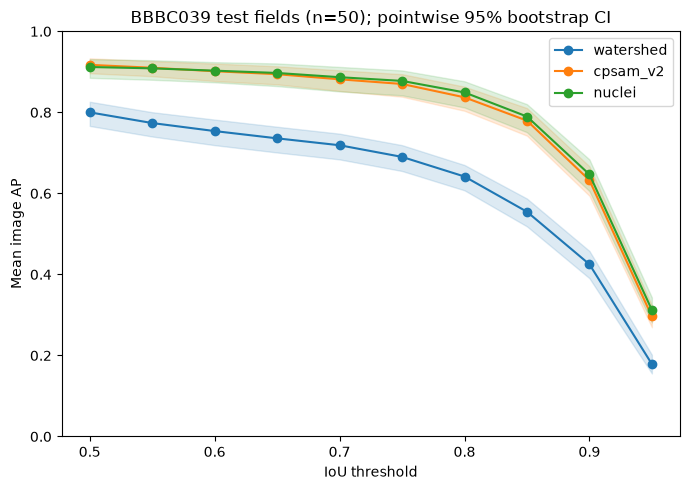

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
for method in METHODS:
    data = curve.loc[curve.method == method]
    line, = ax.plot(data.iou, data["mean"], "o-", label=method)
    ax.fill_between(data.iou, data.ci_low, data.ci_high, color=line.get_color(), alpha=0.15)
ax.set(xlabel="IoU threshold", ylabel="Mean image AP", ylim=(0, 1),
       title="BBBC039 test fields (n=50); pointwise 95% bootstrap CI")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "ap_curve.png", dpi=180)
plt.show()

## Best, median and worst CellposeSAM fields

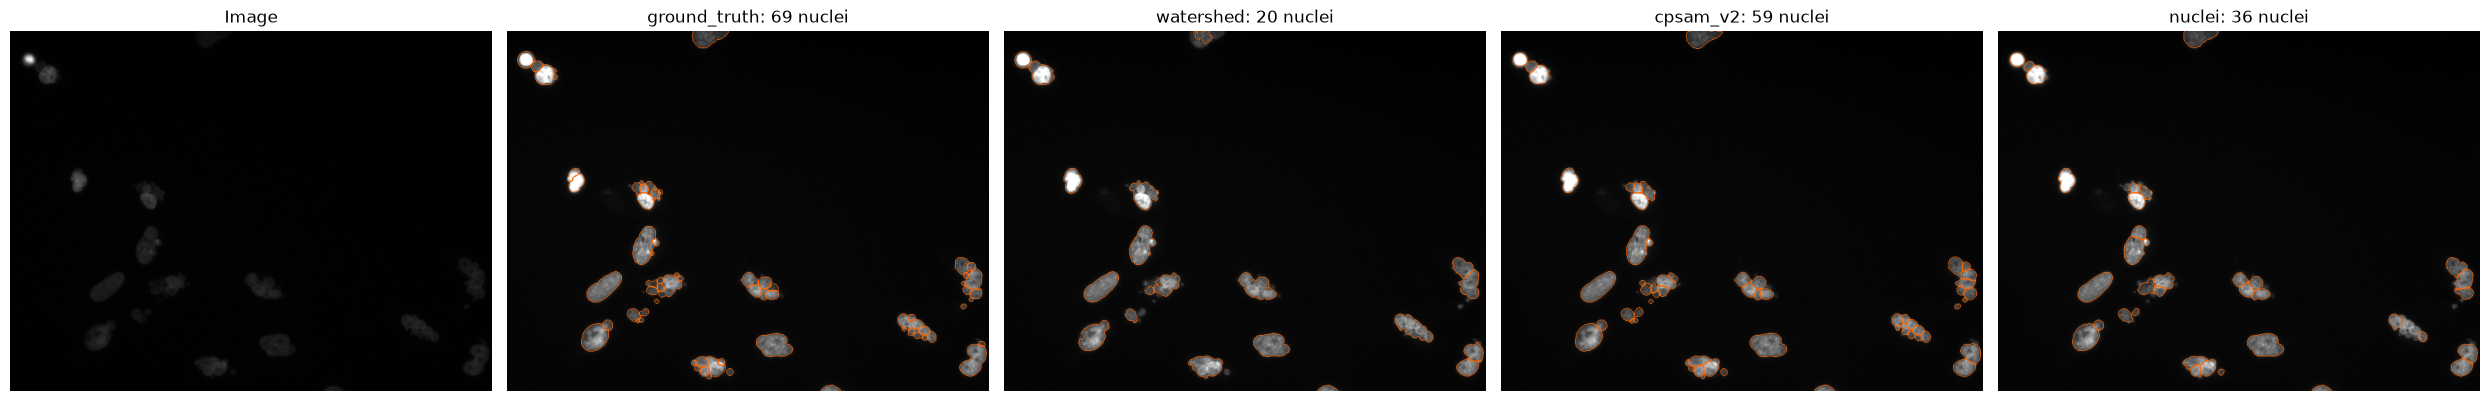

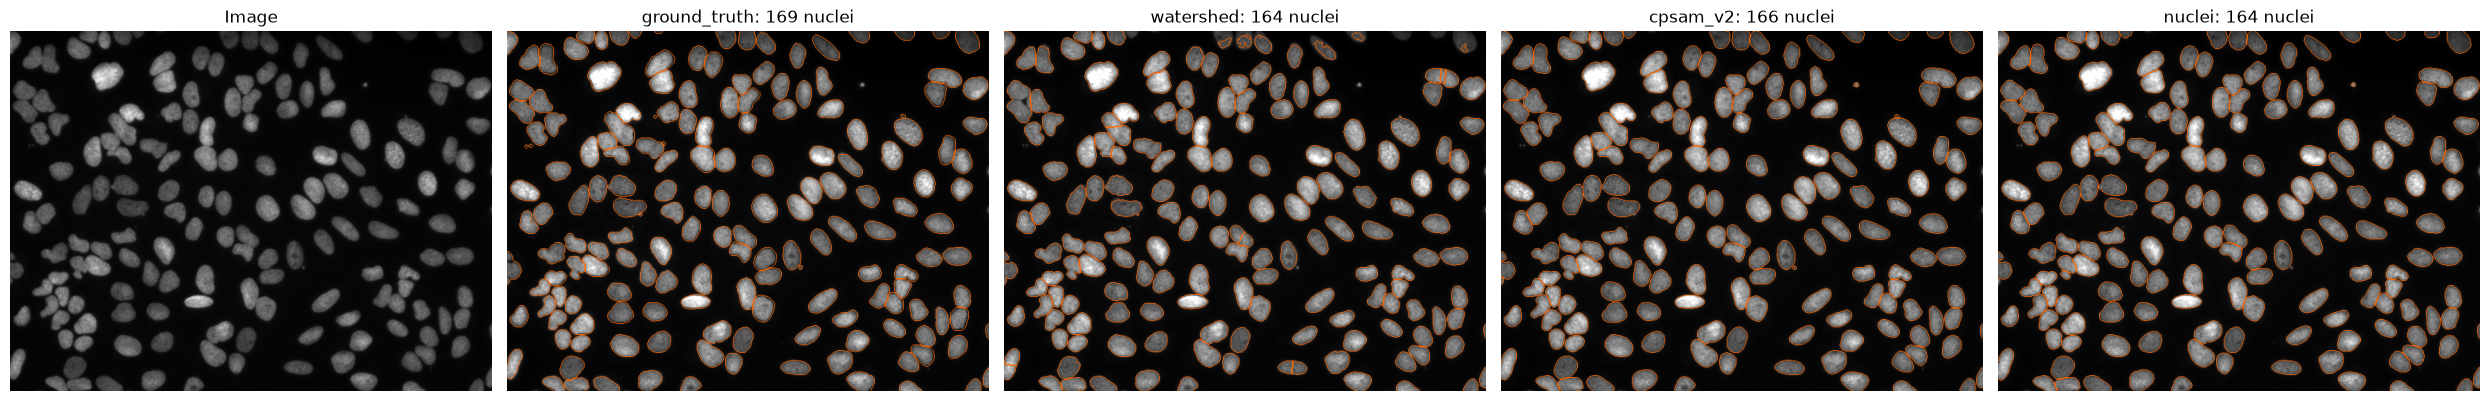

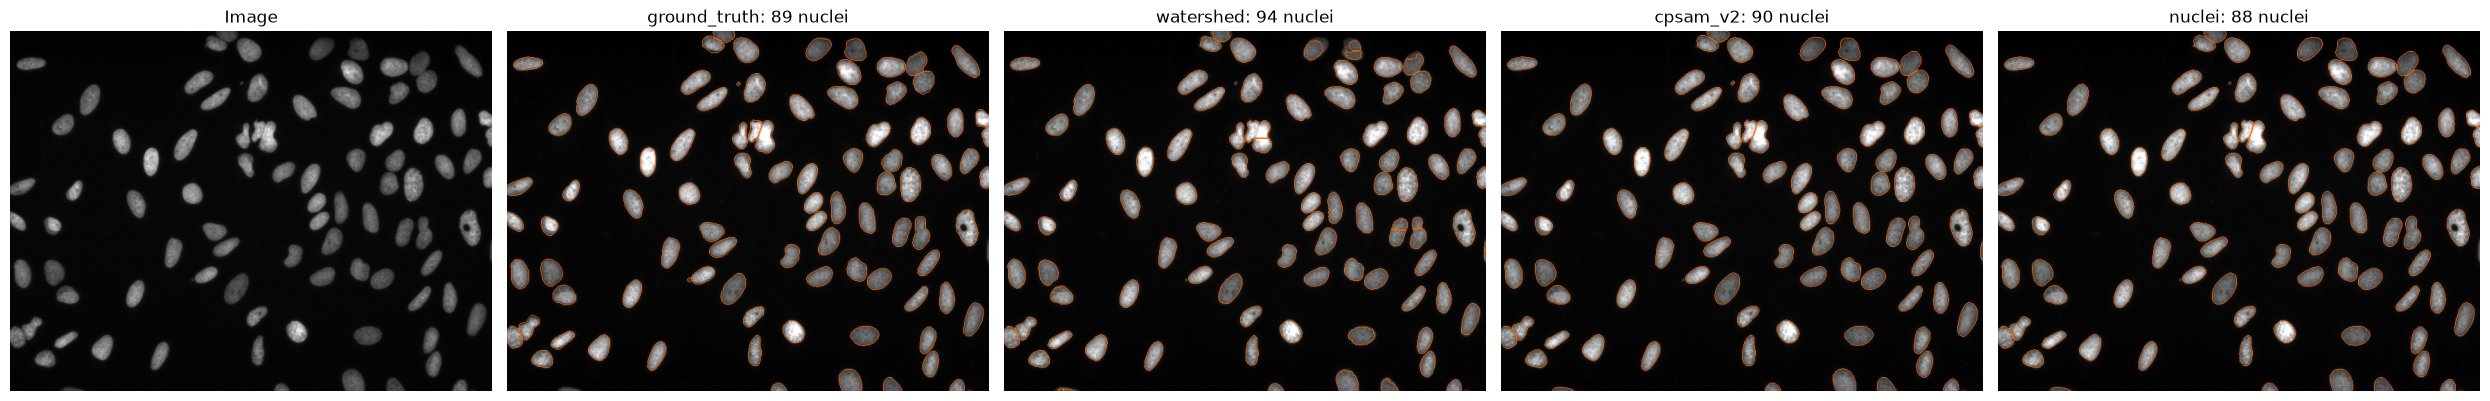

In [11]:
def show_case(stem):
    row = pairs.set_index("stem").loc[stem]
    img = read_zarr_image(row.ome_zarr)
    fig, axes = plt.subplots(1, 2 + len(METHODS), figsize=(5 * (2 + len(METHODS)), 5))
    axes[0].imshow(img, cmap="gray")
    axes[0].set_title("Image")
    for ax, method in zip(axes[1:], ["ground_truth"] + METHODS):
        labels = read_zarr_labels(row.ome_zarr, method)
        ax.imshow(segmentation.mark_boundaries(normalise(img), labels, color=(1, 0.4, 0)))
        ax.set_title(f"{method}: {labels.max()} nuclei")
    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(RESULTS / f"case_{stem}.png", dpi=130)
    plt.show()

ordered = metrics.loc[metrics.method == MODEL_NAME].sort_values("map").reset_index(drop=True)
for index in [0, len(ordered) // 2, len(ordered) - 1]:
    show_case(ordered.iloc[index].stem)

## Density and intensity

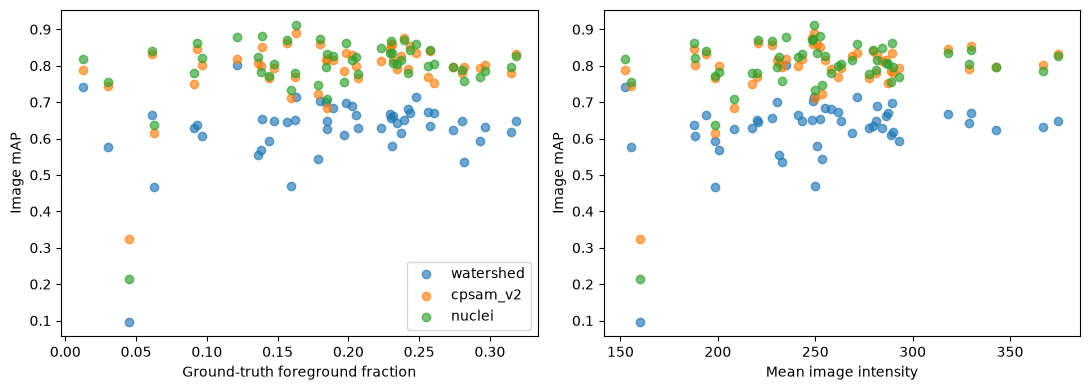

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for method in METHODS:
    data = metrics.loc[metrics.method == method]
    axes[0].scatter(data.cell_density, data["map"], alpha=0.65, label=method)
    axes[1].scatter(data.mean_intensity, data["map"], alpha=0.65, label=method)
axes[0].set(xlabel="Ground-truth foreground fraction", ylabel="Image mAP")
axes[1].set(xlabel="Mean image intensity", ylabel="Image mAP")
axes[0].legend()
fig.tight_layout()
fig.savefig(RESULTS / "density_intensity.png", dpi=180)
plt.show()

## Results

Descriptive strata use quartile cutoffs from the training images: foreground fraction as a crowding proxy, mean image intensity, and the fraction of ground-truth nuclei sharing a pixel edge with another nucleus. Strata overlap and are not causal tests; sample counts are reported. The written summary below updates from the current run.


In [13]:
development_properties = pd.DataFrame([
    dict(cell_density=float((gt > 0).mean()), mean_intensity=float(img.mean()), touching_fraction=touching_fraction(gt))
    for _, img, gt in training_cache
])
cutoffs = {name: development_properties[name].quantile([0.25, 0.75]).tolist()
           for name in ["cell_density", "mean_intensity", "touching_fraction"]}
(RESULTS / "failure_strata_cutoffs.json").write_text(json.dumps(cutoffs, indent=2))
strata = [
    ("high foreground fraction", "cell_density", ">=", cutoffs["cell_density"][1]),
    ("low foreground fraction", "cell_density", "<=", cutoffs["cell_density"][0]),
    ("low mean intensity", "mean_intensity", "<=", cutoffs["mean_intensity"][0]),
    ("high mean intensity", "mean_intensity", ">=", cutoffs["mean_intensity"][1]),
    ("many touching nuclei", "touching_fraction", ">=", cutoffs["touching_fraction"][1]),
    ("few touching nuclei", "touching_fraction", "<=", cutoffs["touching_fraction"][0]),
]
stratum_rows = []
for name, variable, relation, cutoff in strata:
    selected_rows = metrics[variable].ge(cutoff) if relation == ">=" else metrics[variable].le(cutoff)
    for method in METHODS:
        data = metrics.loc[selected_rows & (metrics.method == method)]
        stratum_rows.append(dict(stratum=name, method=method, n_images=len(data), mean_map=data["map"].mean()))
failure_summary = pd.DataFrame(stratum_rows)
failure_summary.to_csv(RESULTS / "failure_strata.csv", index=False)
display(failure_summary.pivot(index="stratum", columns="method", values=["n_images", "mean_map"]))

comparisons = "; ".join(
    f"{row.comparison}: {row.mean:.3f} (95% CI {row.ci_low:.3f} to {row.ci_high:.3f})"
    for row in paired_deltas.itertuples(index=False)
)
lowest = failure_summary.dropna().sort_values("mean_map").groupby("method", sort=False).first()
conditions = "; ".join(f"{method}: {lowest.loc[method, 'stratum']} (mAP {lowest.loc[method, 'mean_map']:.3f}, n={int(lowest.loc[method, 'n_images'])})"
                       for method in METHODS)
statements = []
for row in paired_deltas.itertuples(index=False):
    other = row.comparison.split(" - ", 1)[1]
    if row.ci_low > 0:
        statements.append(f"{MODEL_NAME} has higher mAP than {other}")
    elif row.ci_high < 0:
        statements.append(f"{other} has higher mAP than {MODEL_NAME}")
    else:
        statements.append(f"the {MODEL_NAME} versus {other} difference is unresolved (95% CI includes 0)")
conclusion = "On these fields, " + "; ".join(statements)
interpretation = (
    f"The paired test mAP differences were {comparisons}. "
    f"Among the descriptive strata, the lowest mean mAP occurred for {conditions}, which identifies associations to inspect in the image panels rather than a proven failure mechanism. "
    f"{conclusion}; timings are indicative across CPU/GPU and processes, and unresolved pretraining overlap prevents an independent-generalisation claim."
)
(RESULTS / "results.md").write_text(interpretation + "\n")
display(Markdown(interpretation))


n_images                   mean_map            \
method                   cpsam_v2 nuclei watershed  cpsam_v2    nuclei   
stratum                                                                  
few touching nuclei          13.0   13.0      13.0  0.816516  0.834231   
high foreground fraction     13.0   13.0      13.0  0.801450  0.804000   
high mean intensity           6.0    6.0       6.0  0.819808  0.815742   
low foreground fraction      16.0   16.0      16.0  0.756590  0.767184   
low mean intensity           16.0   16.0      16.0  0.753514  0.757846   
many touching nuclei         12.0   12.0      12.0  0.734913  0.729586   

                                    
method                   watershed  
stratum                             
few touching nuclei       0.652995  
high foreground fraction  0.641603  
high mean intensity       0.647867  
low foreground fraction   0.584662  
low mean intensity        0.588507  
many touching nuclei      0.556137

The paired test mAP differences were cpsam_v2 - watershed: 0.165 (95% CI 0.150 to 0.179); cpsam_v2 - nuclei: -0.006 (95% CI -0.013 to 0.001). Among the descriptive strata, the lowest mean mAP occurred for watershed: many touching nuclei (mAP 0.556, n=12); cpsam_v2: many touching nuclei (mAP 0.735, n=12); nuclei: many touching nuclei (mAP 0.730, n=12), which identifies associations to inspect in the image panels rather than a proven failure mechanism. On these fields, cpsam_v2 has higher mAP than watershed; the cpsam_v2 versus nuclei difference is unresolved (95% CI includes 0); timings are indicative across CPU/GPU and processes, and unresolved pretraining overlap prevents an independent-generalisation claim.

## Nucleus features

In [14]:
feature_tables = []
for row in tqdm(pairs.itertuples(index=False), total=len(pairs)):
    img = read_zarr_image(row.ome_zarr)
    pixel_y, pixel_x = zarr.open_group(row.ome_zarr, mode="r").attrs["pixel_size_um"]
    for method in METHODS:
        pred = read_zarr_labels(row.ome_zarr, method)
        table = pd.DataFrame(measure.regionprops_table(
            pred, intensity_image=img,
            properties=["label", "area", "equivalent_diameter_area", "eccentricity", "solidity", "intensity_mean"],
        ))
        table["area_um2"] = table.area * pixel_y * pixel_x
        table["equivalent_diameter_um"] = np.sqrt(4 * table.area_um2 / np.pi)
        table["stem"], table["method"] = row.stem, method
        feature_tables.append(table)
features = pd.concat(feature_tables, ignore_index=True)
features.to_parquet(RESULTS / "nucleus_features.parquet", index=False)
features.groupby("method")[["area_um2", "intensity_mean"]].describe()

  0%|          | 0/50 [00:00<?, ?it/s]

  2%|▏         | 1/50 [00:00<00:08,  5.67it/s]

  6%|▌         | 3/50 [00:00<00:04, 10.35it/s]

 10%|█         | 5/50 [00:00<00:03, 11.59it/s]

 14%|█▍        | 7/50 [00:00<00:05,  8.02it/s]

...

 90%|█████████ | 45/50 [00:05<00:00, 10.36it/s]

 94%|█████████▍| 47/50 [00:05<00:00, 11.02it/s]

 98%|█████████▊| 49/50 [00:05<00:00, 11.29it/s]

100%|██████████| 50/50 [00:05<00:00,  9.10it/s]

area_um2                                                           \
             count        mean         std       min         25%        50%   
method                                                                        
cpsam_v2    5487.0  261.330422  107.892947  6.240375  213.004800  267.92010   
nuclei      5345.0  263.121919  100.151180  7.904475  215.084925  265.42395   
watershed   5308.0  251.738859  106.043860  5.824350  197.611875  248.78295   

                                   intensity_mean                          \
                  75%          max          count        mean         std   
method                                                                      
cpsam_v2   319.923225   988.475400         5487.0  629.404824  195.699515   
nuclei     317.011050   974.746575         5345.0  637.995213  192.777988   
watershed  304.114275  1075.840650         5308.0  644.364310  165.061838   

                                                                        
                  min         25%         50%         75%          max  
method                                                                  
cpsam_v2   186.294118  505.768841  600.516739  715.418586  2401.017241  
nuclei     237.858824  514.869355  608.220339  723.371917  2361.582492  
watershed  336.956522  532.252567  617.463599  724.542810  2073.784703

## Run record

In [15]:
packages = ["cellpose", "numpy", "torch", "ome-zarr", "zarr", "scikit-image", "scipy", "pandas", "tifffile"]
run_record = {
    "n_images": len(pairs), "split": "official test", "methods": METHODS,
    "training_overlap": "in-distribution/overlap-risk; exact image overlap unresolved",
    "model_sha256": model_sha256, "device": str(model.device),
    "iou_thresholds": IOU_THRESHOLDS.tolist(), "bootstrap_resamples": N_BOOTSTRAP,
    "seed": RANDOM_SEED, "watershed_parameters": WATERSHED,
    "hardware": method_hardware,
    "timing": "indicative; one untimed warm-up per method; GPU synchronization; preprocessing included; loading, process startup and I/O excluded",
    "baseline_selection": "100 training fields: fixed grid; top 3 shortlisted; 50 validation fields select; no test labels",
    "watershed_selection": watershed_selection,
    "legacy_selection": json.loads((RESULTS / "legacy_selection.json").read_text()) if RUN_LEGACY else None,
    "packages": {name: md.version(name) for name in packages},
}
(RESULTS / "run_record.json").write_text(json.dumps(run_record, indent=2))
run_record

{'n_images': 50,
 'split': 'official test',
 'methods': ['watershed', 'cpsam_v2', 'nuclei'],
 'training_overlap': 'in-distribution/overlap-risk; exact image overlap unresolved',
 'model_sha256': '0f1cc3f7ecdd8a037a57c6c48d9d8921391be4cbce3fa9f13c3e3a2e1253c667',
 'device': 'mps',
 'iou_thresholds': [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95],
 'bootstrap_resamples': 10000,
 'seed': 7,
 'watershed_parameters': {'sigma': 0.5, 'min_area': 40, 'min_distance': 9},
 'hardware': {'watershed': {'device': 'cpu',
   'cpu': 'Apple M2 Pro',
   'accelerator': None,
   'memory_bytes': 34359738368,
   'logical_cpus': 10,
   'machine': 'arm64',
   'os': 'macOS-26.6.2-arm64-arm-64bit'},
  'cpsam_v2': {'device': 'mps',
   'cpu': 'Apple M2 Pro',
   'accelerator': 'Apple M2 Pro integrated GPU',
   'memory_bytes': 34359738368,
   'logical_cpus': 10,
   'machine': 'arm64',
   'os': 'macOS-26.6.2-arm64-arm-64bit'},
  'nuclei': {'device': 'mps',
   'cpu': 'Apple M2 Pro',
   'accelerator': 'Apple M

## Napari

In [16]:
RUN_NAPARI = False
if RUN_NAPARI:
    import napari
    row = pairs.iloc[0]
    group = zarr.open_group(row.ome_zarr, mode="r")
    scale = group.attrs["pixel_size_um"]
    viewer = napari.Viewer()
    viewer.add_image(read_zarr_image(row.ome_zarr), name="BBBC039", colormap="gray", scale=scale)
    for method in ["ground_truth"] + METHODS:
        viewer.add_labels(read_zarr_labels(row.ome_zarr, method), name=method, scale=scale, visible=False)
    napari.run()